In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_theme(style="whitegrid")

os.makedirs("../reports/figures", exist_ok=True)

def save(name):
    plt.tight_layout()
    plt.savefig(
        f"../reports/figures/{name}.png",
        dpi=200,
        bbox_inches="tight"
    )
    plt.show()

df = pd.read_csv("../data/processed/clean_v2.csv")

# Category codes must be treated as categories, not numbers
cat_codes = ["owntype", "furnish", "facing", "age"]
df[cat_codes] = df[cat_codes].astype(str)

# Handle the three missing balcony values
df["balcony_num"] = df["balcony_num"].fillna(
    df["balcony_num"].median()
)

# EDA-only helper columns; do not use them as model features
df["price_per_sqft"] = (
    df["price_lakhs"] * 1e5 / df["area_sqft"]
)

df["log_price"] = np.log1p(df["price_lakhs"])

print(df.shape)

df.head()

(7457, 20)


,prop_id,latitude,longitude,property_type,owntype,bedroom_num,bathroom_num,balcony_num,furnish,facing,age,floor_num,total_floor,total_landmark_count,area_sqft,area_is_carpet,locality_grouped,price_lakhs,price_per_sqft,log_price
0,O71585872,28.406534,76.962792,Residential Apartment,1,4.0,4,4.0,4,1,2,14.0,26.0,10.0,3434.0,0,Sector 84 Gurgaon,263.0,7658.707047,5.575949
1,T71585466,28.388907,76.951328,Residential Apartment,1,4.0,4,3.0,4,1,1,7.0,29.0,9.0,2870.0,0,Sector 81 Gurgaon,360.0,12543.554007,5.888878
2,I71493958,28.518677,77.015115,Residential Apartment,1,3.0,3,3.0,4,0,1,14.0,28.0,8.0,2802.0,0,Sector 112 Gurgaon,385.0,13740.185582,5.955837
3,X71361930,28.478440,76.986110,Residential Apartment,1,3.0,4,4.0,4,2,1,4.0,27.0,14.0,2290.0,0,Sector 104 Gurgaon,195.0,8515.283843,5.278115
4,N71483500,28.416400,77.012620,Residential Apartment,1,2.0,2,3.0,2,3,6,12.0,30.0,13.0,1400.0,0,Sector 74 Gurgaon,162.0,11571.428571,5.093750


In [2]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
latitude,7457.0,28.437972,0.041522,28.350930,28.406140,28.425181,28.472552,28.534810
longitude,7457.0,77.040553,0.052859,76.810760,76.997421,77.054558,77.084474,77.191500
bedroom_num,7457.0,3.378839,0.768965,1.000000,3.000000,3.000000,4.000000,8.000000
bathroom_num,7457.0,3.635778,1.020496,0.000000,3.000000,4.000000,4.000000,9.000000
balcony_num,7457.0,2.982433,0.875781,0.000000,2.000000,3.000000,4.000000,4.000000
floor_num,6703.0,7.519171,6.602827,0.000000,2.000000,5.000000,11.000000,48.000000
total_floor,7455.0,15.211133,11.785841,0.000000,4.000000,14.000000,24.000000,51.000000
total_landmark_count,7455.0,22.166063,16.108926,1.000000,10.000000,14.000000,44.000000,50.000000
area_sqft,7457.0,2501.795235,1109.578017,594.000000,1777.000000,2217.000000,2872.000000,10000.000000
area_is_carpet,7457.0,0.255062,0.435925,0.000000,0.000000,0.000000,1.000000,1.000000


In [3]:
df["property_type"].value_counts()

property_type
Residential Apartment        4750
Independent/Builder Floor    2274
Independent House/Villa       433
Name: count, dtype: int64

In [4]:
print("Number of property types:", df["property_type"].nunique())

Number of property types: 3


In [5]:
for c in cat_codes:
    print(c, df[c].value_counts().to_dict())

owntype {'1': 7375, '2': 43, '3': 31, '4': 8}
furnish {'4': 5764, '2': 940, '1': 509, '0': 244}
facing {'5': 2500, '3': 1728, '1': 1045, '0': 833, '4': 468, '6': 269, '7': 262, '2': 181, '8': 171}
age {'1': 2447, '6': 2059, '5': 1255, '2': 1157, '3': 538, '0': 1}


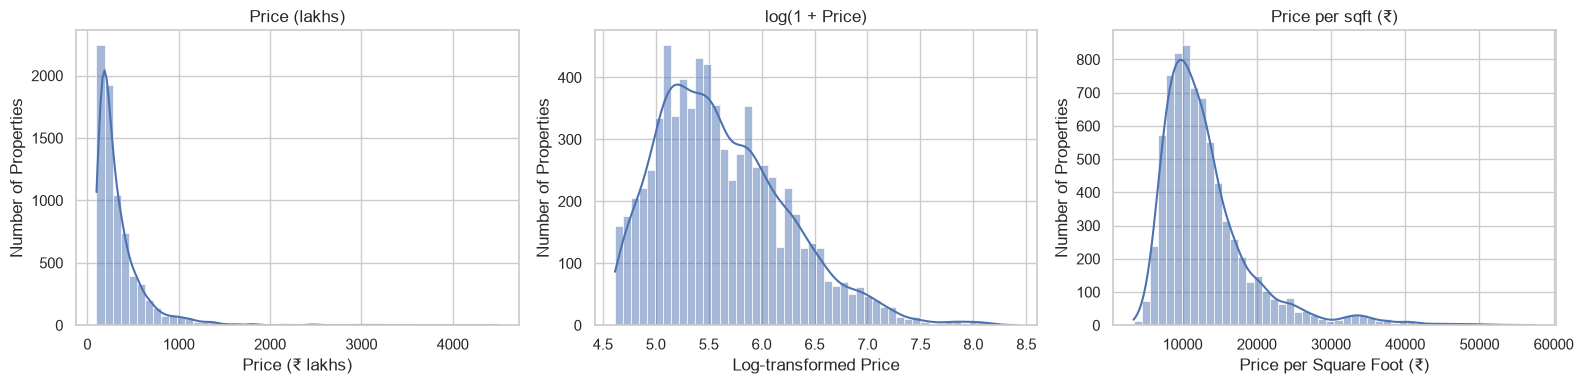

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

sns.histplot(df["price_lakhs"], bins=50, kde=True, ax=ax[0])
ax[0].set_title("Price (lakhs)")
ax[0].set_xlabel("Price (₹ lakhs)")
ax[0].set_ylabel("Number of Properties")

sns.histplot(df["log_price"], bins=50, kde=True, ax=ax[1])
ax[1].set_title("log(1 + Price)")
ax[1].set_xlabel("Log-transformed Price")
ax[1].set_ylabel("Number of Properties")

sns.histplot(df["price_per_sqft"], bins=50, kde=True, ax=ax[2])
ax[2].set_title("Price per sqft (₹)")
ax[2].set_xlabel("Price per Square Foot (₹)")
ax[2].set_ylabel("Number of Properties")

save("01_price_distribution")

In [7]:
print("Skew, raw price: ", round(df["price_lakhs"].skew(), 2))
print("Skew, log price: ", round(df["log_price"].skew(), 2))

print(
    "Mean vs median price:",
    round(df["price_lakhs"].mean(), 1),
    df["price_lakhs"].median()
)

Skew, raw price:  4.2
Skew, log price:  0.77
Mean vs median price: 347.2 250.0


In [8]:
print("Dataset shape:", df.shape)

num_cols = [
    "log_price",
    "area_sqft",
    "bedroom_num",
    "bathroom_num",
    "balcony_num",
    "floor_num",
    "total_floor",
    "total_landmark_count",
    "area_is_carpet",
    "latitude",
    "longitude"
]

missing_cols = [col for col in num_cols if col not in df.columns]

if missing_cols:
    print("Missing columns:", missing_cols)
else:
    print("All required columns are available.")

Dataset shape: (7457, 20)
All required columns are available.


In [9]:
print("Data types:")
print(df[num_cols].dtypes)

print("\nMissing values:")
print(df[num_cols].isnull().sum())

Data types:
log_price               float64
area_sqft               float64
bedroom_num             float64
bathroom_num              int64
balcony_num             float64
floor_num               float64
total_floor             float64
total_landmark_count    float64
area_is_carpet            int64
latitude                float64
longitude               float64
dtype: object

Missing values:
log_price                 0
area_sqft                 0
bedroom_num               0
bathroom_num              0
balcony_num               0
floor_num               754
total_floor               2
total_landmark_count      2
area_is_carpet            0
latitude                  0
longitude                 0
dtype: int64


In [10]:
missing_summary = pd.DataFrame({
    "Missing Count": df[num_cols].isnull().sum(),
    "Missing Percentage": (
        df[num_cols].isnull().mean() * 100
    ).round(2)
})

display(missing_summary)

,Missing Count,Missing Percentage
log_price,0,0.00
area_sqft,0,0.00
bedroom_num,0,0.00
bathroom_num,0,0.00
balcony_num,0,0.00
floor_num,754,10.11
total_floor,2,0.03
total_landmark_count,2,0.03
area_is_carpet,0,0.00
latitude,0,0.00


In [11]:
corr = df[num_cols].corr(method="pearson")

print("Correlation matrix:")
display(corr.round(2))

Correlation matrix:


,log_price,area_sqft,bedroom_num,bathroom_num,balcony_num,floor_num,total_floor,total_landmark_count,area_is_carpet,latitude,longitude
log_price,1.00,0.75,0.62,0.64,0.19,0.19,0.09,0.10,-0.02,0.16,0.47
area_sqft,0.75,1.00,0.66,0.66,0.21,0.09,-0.02,0.11,-0.01,0.14,0.24
bedroom_num,0.62,0.66,1.00,0.81,0.24,-0.05,-0.22,0.22,0.06,0.13,0.19
bathroom_num,0.64,0.66,0.81,1.00,0.30,0.06,-0.07,0.11,-0.04,0.13,0.18
balcony_num,0.19,0.21,0.24,0.30,1.00,0.24,0.25,-0.22,-0.17,-0.02,-0.13
floor_num,0.19,0.09,-0.05,0.06,0.24,1.00,0.70,-0.38,-0.26,-0.07,-0.11
total_floor,0.09,-0.02,-0.22,-0.07,0.25,0.70,1.00,-0.54,-0.26,-0.09,-0.17
total_landmark_count,0.10,0.11,0.22,0.11,-0.22,-0.38,-0.54,1.00,0.26,0.20,0.44
area_is_carpet,-0.02,-0.01,0.06,-0.04,-0.17,-0.26,-0.26,0.26,1.00,0.02,0.16
latitude,0.16,0.14,0.13,0.13,-0.02,-0.07,-0.09,0.20,0.02,1.00,0.09


In [12]:
corr = df[num_cols].corr(method="pearson")

print("Correlation matrix:")
display(corr.round(2))

Correlation matrix:


,log_price,area_sqft,bedroom_num,bathroom_num,balcony_num,floor_num,total_floor,total_landmark_count,area_is_carpet,latitude,longitude
log_price,1.00,0.75,0.62,0.64,0.19,0.19,0.09,0.10,-0.02,0.16,0.47
area_sqft,0.75,1.00,0.66,0.66,0.21,0.09,-0.02,0.11,-0.01,0.14,0.24
bedroom_num,0.62,0.66,1.00,0.81,0.24,-0.05,-0.22,0.22,0.06,0.13,0.19
bathroom_num,0.64,0.66,0.81,1.00,0.30,0.06,-0.07,0.11,-0.04,0.13,0.18
balcony_num,0.19,0.21,0.24,0.30,1.00,0.24,0.25,-0.22,-0.17,-0.02,-0.13
floor_num,0.19,0.09,-0.05,0.06,0.24,1.00,0.70,-0.38,-0.26,-0.07,-0.11
total_floor,0.09,-0.02,-0.22,-0.07,0.25,0.70,1.00,-0.54,-0.26,-0.09,-0.17
total_landmark_count,0.10,0.11,0.22,0.11,-0.22,-0.38,-0.54,1.00,0.26,0.20,0.44
area_is_carpet,-0.02,-0.01,0.06,-0.04,-0.17,-0.26,-0.26,0.26,1.00,0.02,0.16
latitude,0.16,0.14,0.13,0.13,-0.02,-0.07,-0.09,0.20,0.02,1.00,0.09


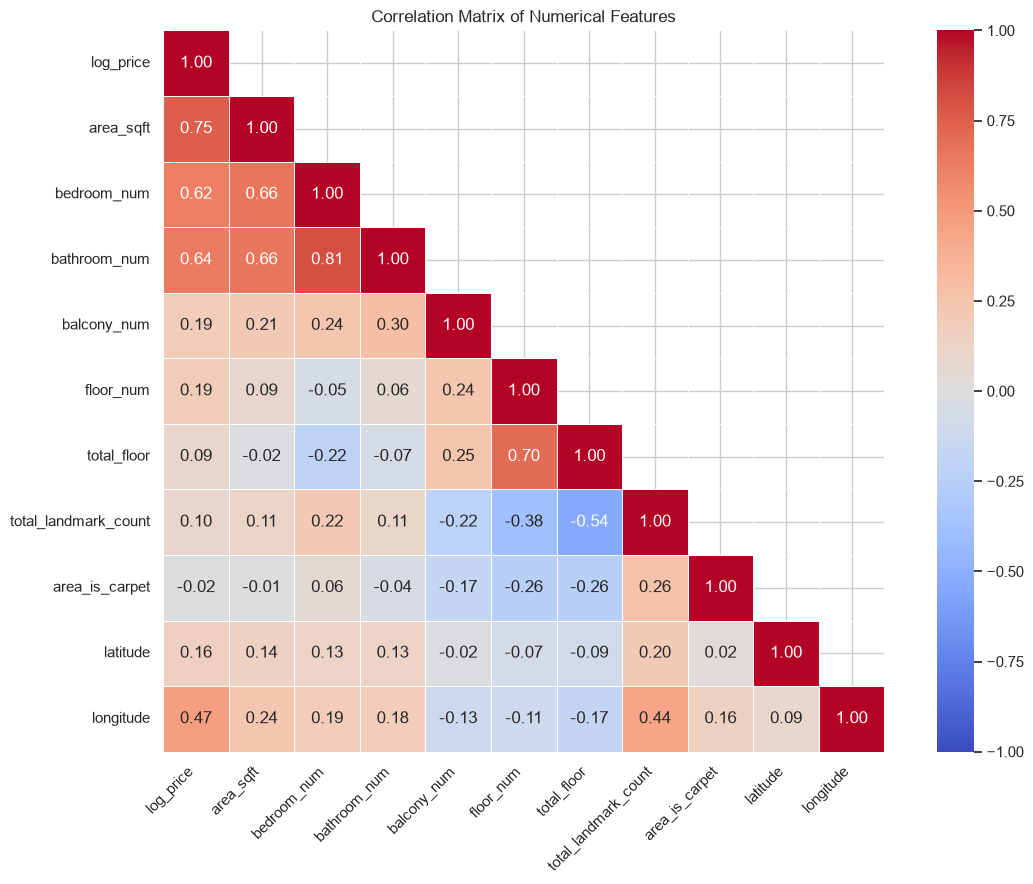

In [13]:
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

plt.figure(figsize=(12, 9))

sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5
)

plt.title("Correlation Matrix of Numerical Features")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

save("02_correlation_heatmap")

In [14]:
price_corr = (
    corr["log_price"]
    .drop("log_price")
    .sort_values(ascending=False)
)

print("Correlation with log_price:")
display(price_corr.to_frame("correlation").round(3))

Correlation with log_price:


,correlation
area_sqft,0.752
bathroom_num,0.640
bedroom_num,0.623
longitude,0.469
floor_num,0.189
balcony_num,0.189
latitude,0.158
total_landmark_count,0.099
total_floor,0.089
area_is_carpet,-0.015


In [15]:
# Exclude log_price because this check is for relationships
# between predictor variables.
feature_cols = [col for col in num_cols if col != "log_price"]

feature_corr = df[feature_cols].corr(method="pearson")

# Keep only the upper triangle so each pair appears once.
upper = feature_corr.where(
    np.triu(np.ones(feature_corr.shape), k=1).astype(bool)
)

# Find pairs with absolute correlation greater than 0.8.
strong_pairs = (
    upper.stack()
    .reset_index()
)

strong_pairs.columns = ["Feature 1", "Feature 2", "Correlation"]

strong_pairs = strong_pairs[
    strong_pairs["Correlation"].abs() > 0.8
].sort_values(
    by="Correlation",
    key=lambda x: x.abs(),
    ascending=False
)

if strong_pairs.empty:
    print("No predictor pairs have an absolute correlation above 0.8.")
else:
    print("Strongly correlated predictor pairs:")
    display(strong_pairs.round(3))

Strongly correlated predictor pairs:


,Feature 1,Feature 2,Correlation
12,bedroom_num,bathroom_num,0.807


In [16]:
print("area_is_carpet value counts:")
print(df["area_is_carpet"].value_counts(dropna=False))

print("\nCorrelation with log_price:")
print(round(df["area_is_carpet"].corr(df["log_price"]), 3))

area_is_carpet value counts:
area_is_carpet
0    5555
1    1902
Name: count, dtype: int64

Correlation with log_price:
-0.015


In [17]:
print("=" * 55)
print("PART D: CORRELATION HEATMAP — RESULTS")
print("=" * 55)

print("\n1. Correlation with log_price:")
display(price_corr.to_frame("correlation").round(3))

print("\n2. Strongly correlated predictor pairs:")
if strong_pairs.empty:
    print("No pairs exceeded the absolute correlation threshold of 0.8.")
else:
    display(strong_pairs.round(3))

print("\n3. Latitude vs log_price:",
      round(df["latitude"].corr(df["log_price"]), 3))

print("4. Longitude vs log_price:",
      round(df["longitude"].corr(df["log_price"]), 3))

print("5. area_is_carpet vs log_price:",
      round(df["area_is_carpet"].corr(df["log_price"]), 3))

PART D: CORRELATION HEATMAP — RESULTS

1. Correlation with log_price:


,correlation
area_sqft,0.752
bathroom_num,0.640
bedroom_num,0.623
longitude,0.469
floor_num,0.189
balcony_num,0.189
latitude,0.158
total_landmark_count,0.099
total_floor,0.089
area_is_carpet,-0.015



2. Strongly correlated predictor pairs:


,Feature 1,Feature 2,Correlation
12,bedroom_num,bathroom_num,0.807



3. Latitude vs log_price: 0.158
4. Longitude vs log_price: 0.469
5. area_is_carpet vs log_price: -0.015


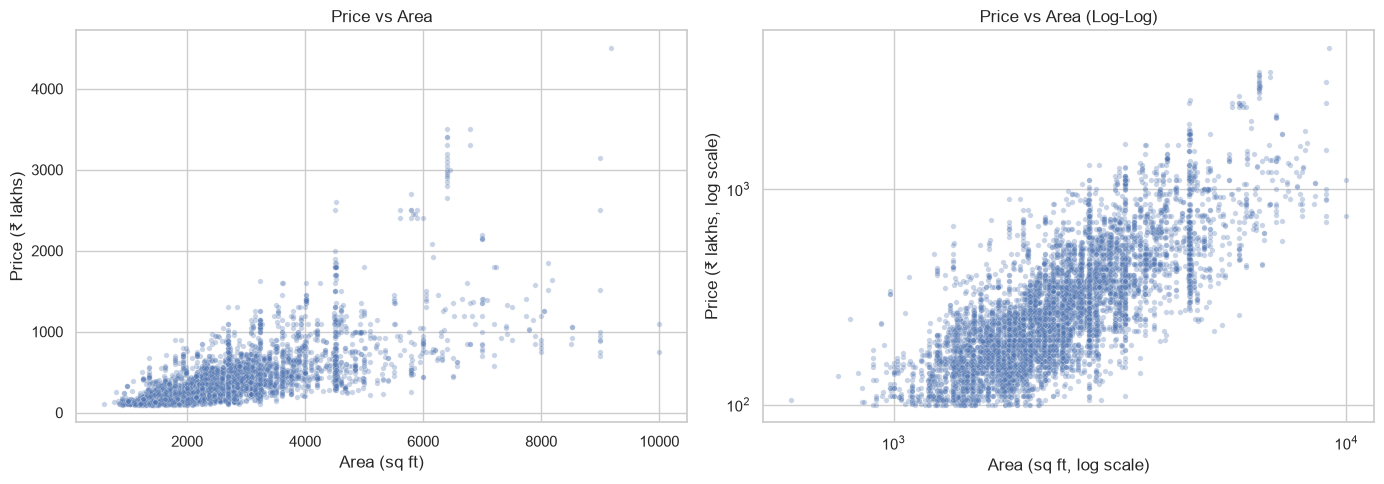

In [18]:
# Price vs area: original scale and log-log scale

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Original scale
sns.scatterplot(
    data=df,
    x="area_sqft",
    y="price_lakhs",
    alpha=0.3,
    s=15,
    ax=ax[0]
)

ax[0].set_title("Price vs Area")
ax[0].set_xlabel("Area (sq ft)")
ax[0].set_ylabel("Price (₹ lakhs)")

# Plot 2: Log-log scale
sns.scatterplot(
    data=df,
    x="area_sqft",
    y="price_lakhs",
    alpha=0.3,
    s=15,
    ax=ax[1]
)

ax[1].set_xscale("log")
ax[1].set_yscale("log")
ax[1].set_title("Price vs Area (Log-Log)")
ax[1].set_xlabel("Area (sq ft, log scale)")
ax[1].set_ylabel("Price (₹ lakhs, log scale)")

save("03a_price_vs_area")

In [19]:
print(
    "Pearson correlation (area vs log_price):",
    round(df["area_sqft"].corr(df["log_price"]), 3)
)

print(
    "Spearman correlation (area vs log_price):",
    round(df["area_sqft"].corr(df["log_price"], method="spearman"), 3)
)

Pearson correlation (area vs log_price): 0.752
Spearman correlation (area vs log_price): 0.763


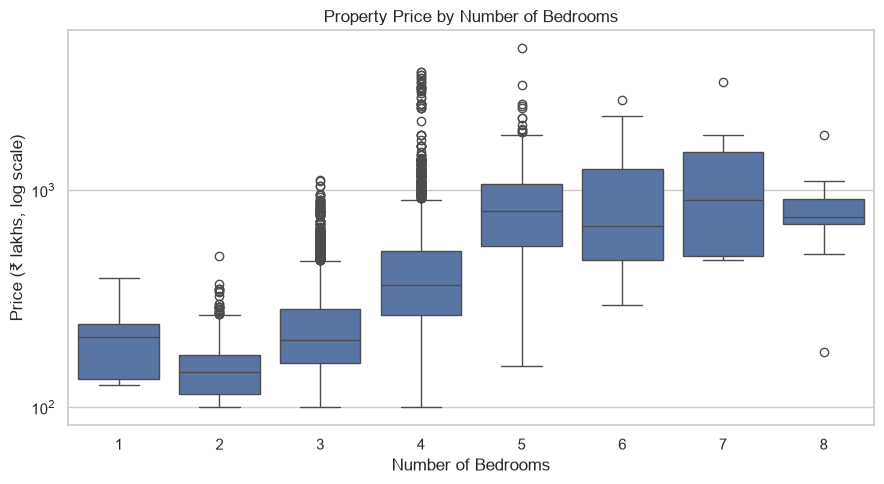

In [20]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x=df["bedroom_num"].astype(int),
    y="price_lakhs"
)

plt.yscale("log")
plt.xlabel("Number of Bedrooms")
plt.ylabel("Price (₹ lakhs, log scale)")
plt.title("Property Price by Number of Bedrooms")

save("03b_price_vs_bedrooms")

In [21]:
bedroom_counts = (
    df["bedroom_num"]
    .value_counts()
    .sort_index()
)

print("Number of properties by bedroom count:")
display(bedroom_counts.to_frame("Property Count"))

Number of properties by bedroom count:


,Property Count
bedroom_num,
1.0,7
2.0,663
3.0,3769
4.0,2644
5.0,303
6.0,42
7.0,19
8.0,10


In [22]:
bedroom_stats = (
    df.groupby("bedroom_num")["price_lakhs"]
    .agg(["count", "median", "mean", "min", "max"])
    .round(2)
)

print("Price statistics by bedroom count:")
display(bedroom_stats)

Price statistics by bedroom count:


,count,median,mean,min,max
bedroom_num,,,,,
1.0,7,210.0,212.00,127.0,395.0
2.0,663,145.0,154.41,100.0,500.0
3.0,3769,205.0,247.37,100.0,1119.0
4.0,2644,367.5,461.74,100.0,3500.0
5.0,303,800.0,876.27,155.0,4500.0
6.0,42,687.5,923.45,295.0,2600.0
7.0,19,900.0,1034.21,475.0,3150.0
8.0,10,750.0,822.90,180.0,1800.0


Property counts:


,Property Count
property_type,
Residential Apartment,4750
Independent/Builder Floor,2274
Independent House/Villa,433


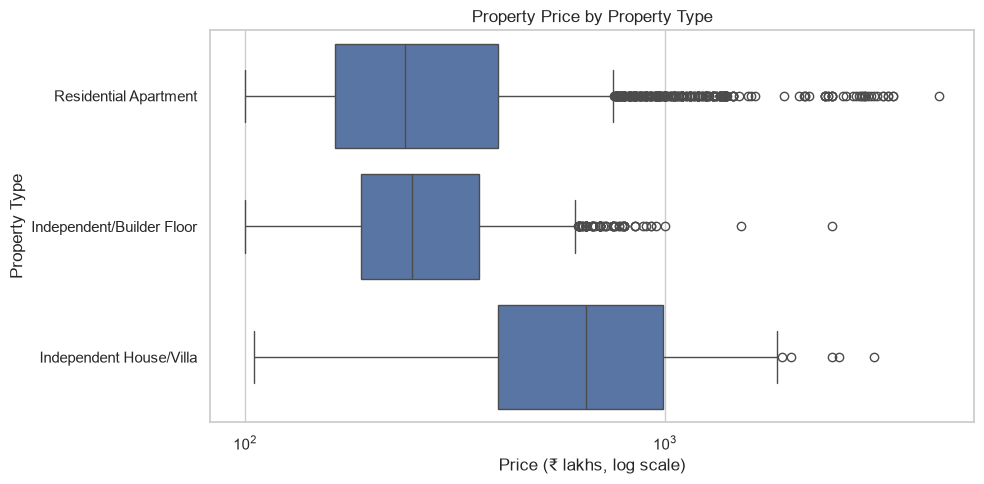

In [23]:
# Count listings for each property type
counts = df["property_type"].value_counts()

print("Property counts:")
display(counts.to_frame("Property Count"))

# Keep property types with at least 30 listings
types = counts[counts >= 30].index

sub = df[df["property_type"].isin(types)].copy()

# Order property types by median price
order = (
    sub.groupby("property_type")["price_lakhs"]
    .median()
    .sort_values()
    .index
)

# Create the boxplot
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=sub,
    y="property_type",
    x="price_lakhs",
    order=order
)

plt.xscale("log")
plt.xlabel("Price (₹ lakhs, log scale)")
plt.ylabel("Property Type")
plt.title("Property Price by Property Type")

save("03c_price_by_property_type")

In [24]:
property_type_stats = (
    sub.groupby("property_type")["price_lakhs"]
    .agg(["count", "median", "mean", "min", "max"])
    .sort_values("median")
    .round(2)
)

print("Price statistics by property type:")
display(property_type_stats)

Price statistics by property type:


,count,median,mean,min,max
property_type,,,,,
Residential Apartment,4750,240.0,339.73,100.0,4500.0
Independent/Builder Floor,2274,250.0,290.70,100.0,2500.0
Independent House/Villa,433,650.0,726.24,105.0,3150.0


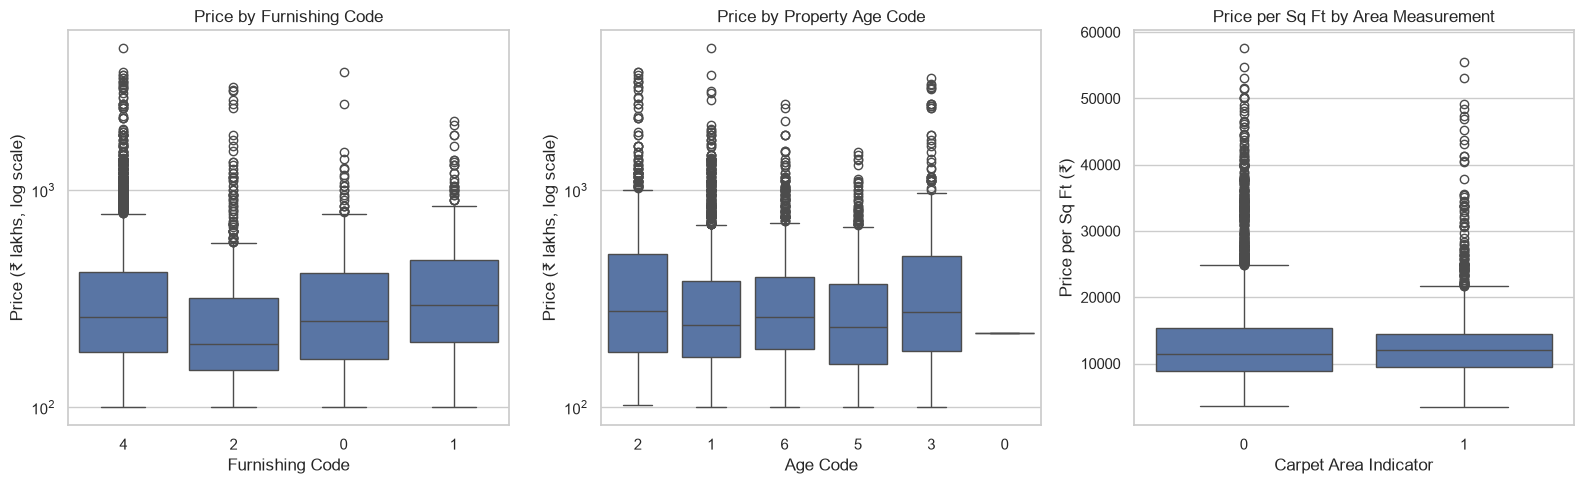

In [25]:
fig, ax = plt.subplots(1, 3, figsize=(16, 5))

# Plot 1: Price by furnishing code
sns.boxplot(
    data=df,
    x="furnish",
    y="price_lakhs",
    ax=ax[0]
)

ax[0].set_yscale("log")
ax[0].set_title("Price by Furnishing Code")
ax[0].set_xlabel("Furnishing Code")
ax[0].set_ylabel("Price (₹ lakhs, log scale)")

# Plot 2: Price by age code
sns.boxplot(
    data=df,
    x="age",
    y="price_lakhs",
    ax=ax[1]
)

ax[1].set_yscale("log")
ax[1].set_title("Price by Property Age Code")
ax[1].set_xlabel("Age Code")
ax[1].set_ylabel("Price (₹ lakhs, log scale)")

# Plot 3: Price per square foot by carpet-area indicator
sns.boxplot(
    data=df,
    x="area_is_carpet",
    y="price_per_sqft",
    ax=ax[2]
)

ax[2].set_title("Price per Sq Ft by Area Measurement")
ax[2].set_xlabel("Carpet Area Indicator")
ax[2].set_ylabel("Price per Sq Ft (₹)")

save("03d_other_categoricals")

In [26]:
print("Furnishing code counts:")
display(df["furnish"].value_counts().sort_index().to_frame("Count"))

print("Property age code counts:")
display(df["age"].value_counts().sort_index().to_frame("Count"))

print("Carpet-area indicator counts:")
display(
    df["area_is_carpet"]
    .value_counts(dropna=False)
    .sort_index()
    .to_frame("Count")
)

Furnishing code counts:


,Count
furnish,
0,244
1,509
2,940
4,5764


Property age code counts:


,Count
age,
0,1
1,2447
2,1157
3,538
5,1255
6,2059


Carpet-area indicator counts:


,Count
area_is_carpet,
0,5555
1,1902


In [27]:
print("Median price by furnishing code:")
display(
    df.groupby("furnish")["price_lakhs"]
    .agg(["count", "median"])
    .round(2)
)

print("Median price by property age code:")
display(
    df.groupby("age")["price_lakhs"]
    .agg(["count", "median"])
    .round(2)
)

print("Median price per square foot by area measurement:")
display(
    df.groupby("area_is_carpet")["price_per_sqft"]
    .agg(["count", "median"])
    .round(2)
)

Median price by furnishing code:


,count,median
furnish,,
0,244,250.5
1,509,295.0
2,940,195.5
4,5764,260.0


Median price by property age code:


,count,median
age,,
0,1,220.0
1,2447,240.0
2,1157,279.0
3,538,275.0
5,1255,234.0
6,2059,260.0


Median price per square foot by area measurement:


,count,median
area_is_carpet,,
0,5555,11469.07
1,1902,12000.00


In [28]:
import os

figure_files = [
    "03a_price_vs_area.png",
    "03b_price_vs_bedrooms.png",
    "03c_price_by_property_type.png",
    "03d_other_categoricals.png"
]

for filename in figure_files:
    filepath = os.path.join("../reports/figures", filename)

    print(
        filename,
        "— Saved" if os.path.exists(filepath) else "— Not found"
    )

03a_price_vs_area.png — Saved
03b_price_vs_bedrooms.png — Saved
03c_price_by_property_type.png — Saved
03d_other_categoricals.png — Saved


In [29]:
required_cols = [
    "locality_grouped",
    "price_lakhs",
    "price_per_sqft"
]

missing_cols = [
    col for col in required_cols
    if col not in df.columns
]

if missing_cols:
    print("Missing columns:", missing_cols)
else:
    print("All required columns are available.")

print("\nDataset shape:", df.shape)

print("\nMissing values:")
print(df[required_cols].isnull().sum())

print("\nNumber of localities:", df["locality_grouped"].nunique())

All required columns are available.

Dataset shape: (7457, 20)

Missing values:
locality_grouped    0
price_lakhs         0
price_per_sqft      0
dtype: int64

Number of localities: 106


In [30]:
loc = (
    df[df["locality_grouped"] != "Other"]
    .groupby("locality_grouped")
    .agg(
        listings=("price_lakhs", "size"),
        median_price=("price_lakhs", "median"),
        mean_price=("price_lakhs", "mean"),
        median_pps=("price_per_sqft", "median")
    )
    .query("listings >= 15")
    .sort_values("median_price", ascending=False)
)

print("Localities analysed:", len(loc))

print("\nLocality statistics:")
display(loc.round(2))

Localities analysed: 96

Locality statistics:


,listings,median_price,mean_price,median_pps
locality_grouped,,,,
Sector 42 Gurgaon,46,2500.0,2132.63,42980.30
Sector 33 Gurgaon,24,987.5,718.92,20151.52
Sector 54 Gurgaon,216,725.0,821.53,24843.52
MG Road,18,650.5,666.83,22222.22
Sector 53 Gurgaon,81,549.0,574.06,19387.76
...,...,...,...,...
Sector 103 Gurgaon,52,126.5,142.27,7811.96
Sector 37C Gurgaon,47,125.0,132.81,6916.43
Sector 89 Gurgaon,15,125.0,124.67,8569.30


In [31]:
top10_price = loc.nlargest(10, "median_price")

bottom10_price = loc.nsmallest(10, "median_price")

print("TOP 10 LOCALITIES BY MEDIAN SALE PRICE")
display(top10_price.round(2))

print("\nBOTTOM 10 LOCALITIES BY MEDIAN SALE PRICE")
display(bottom10_price.round(2))

TOP 10 LOCALITIES BY MEDIAN SALE PRICE


,listings,median_price,mean_price,median_pps
locality_grouped,,,,
Sector 42 Gurgaon,46,2500.0,2132.63,42980.30
Sector 33 Gurgaon,24,987.5,718.92,20151.52
Sector 54 Gurgaon,216,725.0,821.53,24843.52
MG Road,18,650.5,666.83,22222.22
Sector 53 Gurgaon,81,549.0,574.06,19387.76
Sector 112 Gurgaon,56,545.5,598.80,12486.95
Sector 26 Gurgaon,24,512.5,615.00,16228.24
Sector 59 Gurgaon,142,502.5,503.30,18247.25
DLF Phase 5,100,499.5,454.25,18716.64



BOTTOM 10 LOCALITIES BY MEDIAN SALE PRICE


,listings,median_price,mean_price,median_pps
locality_grouped,,,,
Sector 95 Gurgaon,22,115.0,130.82,6791.81
Sector 68 Gurgaon,59,120.0,132.00,8976.38
Sector 37C Gurgaon,47,125.0,132.81,6916.43
Sector 89 Gurgaon,15,125.0,124.67,8569.30
Sector 103 Gurgaon,52,126.5,142.27,7811.96
Sector 71 Gurgaon,42,127.5,133.31,6936.38
Sector 93 Gurgaon,50,137.0,135.80,9017.73
Sector 107 Gurgaon,25,140.0,149.88,7514.15
Sector 82 Gurgaon,72,141.0,198.06,7266.07


In [32]:
def top_bottom(metric, title, fname):
    top = loc.nlargest(10, metric).sort_values(metric)
    bottom = loc.nsmallest(10, metric).sort_values(metric)

    fig, ax = plt.subplots(1, 2, figsize=(15, 6))

    sns.barplot(
        data=top.reset_index(),
        x=metric,
        y="locality_grouped",
        ax=ax[0],
        color="tab:red"
    )

    ax[0].set_title(f"Top 10 Localities: {title}")
    ax[0].set_xlabel(title)
    ax[0].set_ylabel("Locality")

    sns.barplot(
        data=bottom.reset_index(),
        x=metric,
        y="locality_grouped",
        ax=ax[1],
        color="tab:blue"
    )

    ax[1].set_title(f"Bottom 10 Localities: {title}")
    ax[1].set_xlabel(title)
    ax[1].set_ylabel("Locality")

    save(fname)

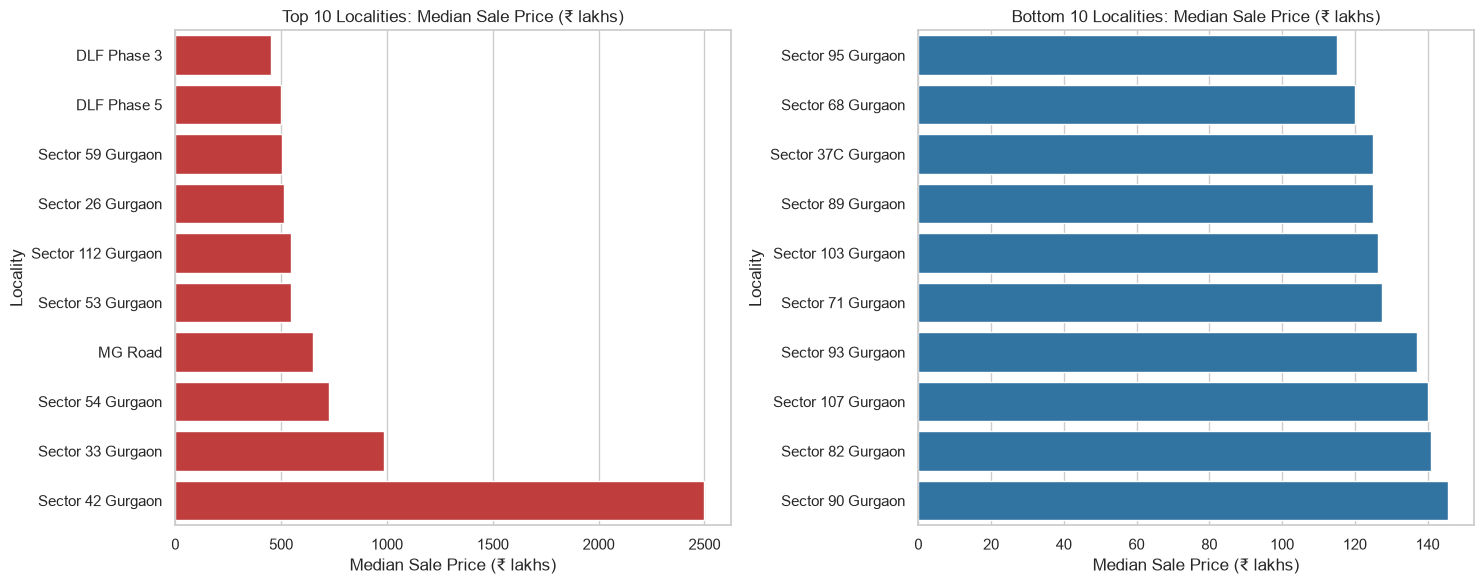

In [33]:
top_bottom(
    "median_price",
    "Median Sale Price (₹ lakhs)",
    "04a_locality_median_price"
)

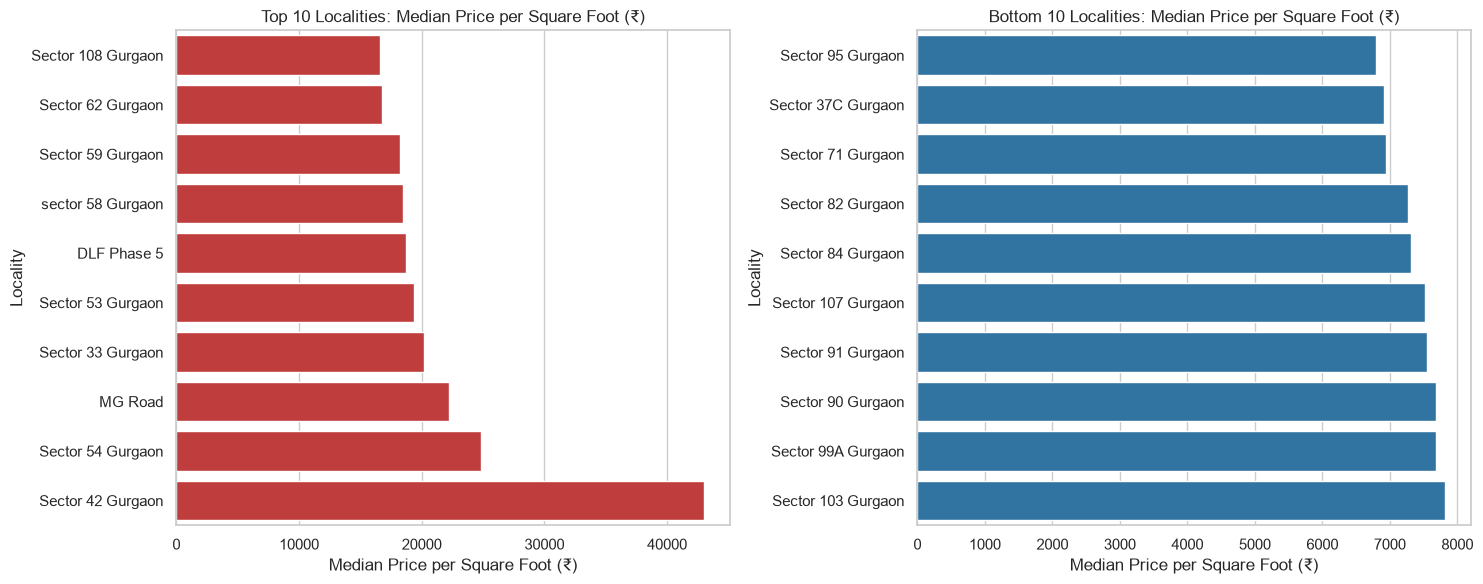

In [34]:
top_bottom(
    "median_pps",
    "Median Price per Square Foot (₹)",
    "04b_locality_median_pps"
)

In [35]:
highest_pps = loc["median_pps"].max()
lowest_pps = loc["median_pps"].min()

highest_pps_locality = loc["median_pps"].idxmax()
lowest_pps_locality = loc["median_pps"].idxmin()

print("Highest median price per sqft:")
print("Locality:", highest_pps_locality)
print("Price: ₹", round(highest_pps, 2))

print("\nLowest median price per sqft:")
print("Locality:", lowest_pps_locality)
print("Price: ₹", round(lowest_pps, 2))

if lowest_pps > 0:
    ratio_pps = highest_pps / lowest_pps

    print("\nHighest-to-lowest price per sqft ratio:",
          round(ratio_pps, 2), "x")

Highest median price per sqft:
Locality: Sector 42 Gurgaon
Price: ₹ 42980.3

Lowest median price per sqft:
Locality: Sector 95 Gurgaon
Price: ₹ 6791.81

Highest-to-lowest price per sqft ratio: 6.33 x


In [36]:
ranking_comparison = loc[
    ["listings", "median_price", "median_pps"]
].copy()

ranking_comparison["price_rank"] = (
    ranking_comparison["median_price"]
    .rank(ascending=False, method="min")
    .astype(int)
)

ranking_comparison["price_per_sqft_rank"] = (
    ranking_comparison["median_pps"]
    .rank(ascending=False, method="min")
    .astype(int)
)

ranking_comparison["rank_difference"] = (
    ranking_comparison["price_rank"]
    - ranking_comparison["price_per_sqft_rank"]
)

ranking_comparison = ranking_comparison.sort_values("price_rank")

display(ranking_comparison.round(2))

,listings,median_price,median_pps,price_rank,price_per_sqft_rank,rank_difference
locality_grouped,,,,,,
Sector 42 Gurgaon,46,2500.0,42980.30,1,1,0
Sector 33 Gurgaon,24,987.5,20151.52,2,4,-2
Sector 54 Gurgaon,216,725.0,24843.52,3,2,1
MG Road,18,650.5,22222.22,4,3,1
Sector 53 Gurgaon,81,549.0,19387.76,5,5,0
...,...,...,...,...,...,...
Sector 103 Gurgaon,52,126.5,7811.96,92,87,5
Sector 37C Gurgaon,47,125.0,6916.43,93,95,-2
Sector 89 Gurgaon,15,125.0,8569.30,93,83,10


In [37]:
print("LISTING COUNTS — TOP 10 BY MEDIAN PRICE")

display(
    loc.nlargest(10, "median_price")[["listings", "median_price"]]
    .round(2)
)

print("\nLISTING COUNTS — BOTTOM 10 BY MEDIAN PRICE")

display(
    loc.nsmallest(10, "median_price")[["listings", "median_price"]]
    .round(2)
)

print("\nLISTING COUNTS — TOP 10 BY MEDIAN PRICE PER SQFT")

display(
    loc.nlargest(10, "median_pps")[["listings", "median_pps"]]
    .round(2)
)

print("\nLISTING COUNTS — BOTTOM 10 BY MEDIAN PRICE PER SQFT")

display(
    loc.nsmallest(10, "median_pps")[["listings", "median_pps"]]
    .round(2)
)

LISTING COUNTS — TOP 10 BY MEDIAN PRICE


,listings,median_price
locality_grouped,,
Sector 42 Gurgaon,46,2500.0
Sector 33 Gurgaon,24,987.5
Sector 54 Gurgaon,216,725.0
MG Road,18,650.5
Sector 53 Gurgaon,81,549.0
Sector 112 Gurgaon,56,545.5
Sector 26 Gurgaon,24,512.5
Sector 59 Gurgaon,142,502.5
DLF Phase 5,100,499.5



LISTING COUNTS — BOTTOM 10 BY MEDIAN PRICE


,listings,median_price
locality_grouped,,
Sector 95 Gurgaon,22,115.0
Sector 68 Gurgaon,59,120.0
Sector 37C Gurgaon,47,125.0
Sector 89 Gurgaon,15,125.0
Sector 103 Gurgaon,52,126.5
Sector 71 Gurgaon,42,127.5
Sector 93 Gurgaon,50,137.0
Sector 107 Gurgaon,25,140.0
Sector 82 Gurgaon,72,141.0



LISTING COUNTS — TOP 10 BY MEDIAN PRICE PER SQFT


,listings,median_pps
locality_grouped,,
Sector 42 Gurgaon,46,42980.30
Sector 54 Gurgaon,216,24843.52
MG Road,18,22222.22
Sector 33 Gurgaon,24,20151.52
Sector 53 Gurgaon,81,19387.76
DLF Phase 5,100,18716.64
sector 58 Gurgaon,28,18499.21
Sector 59 Gurgaon,142,18247.25
Sector 62 Gurgaon,115,16781.84



LISTING COUNTS — BOTTOM 10 BY MEDIAN PRICE PER SQFT


,listings,median_pps
locality_grouped,,
Sector 95 Gurgaon,22,6791.81
Sector 37C Gurgaon,47,6916.43
Sector 71 Gurgaon,42,6936.38
Sector 82 Gurgaon,72,7266.07
Sector 84 Gurgaon,81,7314.29
Sector 107 Gurgaon,25,7514.15
Sector 91 Gurgaon,40,7545.65
Sector 90 Gurgaon,68,7683.63
Sector 99A Gurgaon,18,7686.53


In [38]:
import os

figure_files = [
    "04a_locality_median_price.png",
    "04b_locality_median_pps.png"
]

for filename in figure_files:
    filepath = os.path.join("../reports/figures", filename)

    print(
        filename,
        "— Saved" if os.path.exists(filepath) else "— Not found"
    )

04a_locality_median_price.png — Saved
04b_locality_median_pps.png — Saved


In [39]:
print("=" * 60)
print("PART F: LOCALITY PRICE ANALYSIS")
print("=" * 60)

print("\nNumber of localities analysed:", len(loc))

print("\nHighest median sale price:")
display(loc.nlargest(1, "median_price"))

print("\nLowest median sale price:")
display(loc.nsmallest(1, "median_price"))

print("\nHighest median price per sqft:")
display(loc.nlargest(1, "median_pps"))

print("\nLowest median price per sqft:")
display(loc.nsmallest(1, "median_pps"))

print("\nTop 10 by median sale price:")
display(loc.nlargest(10, "median_price").round(2))

print("\nBottom 10 by median sale price:")
display(loc.nsmallest(10, "median_price").round(2))

print("\nTop 10 by median price per sqft:")
display(loc.nlargest(10, "median_pps").round(2))

print("\nBottom 10 by median price per sqft:")
display(loc.nsmallest(10, "median_pps").round(2))

PART F: LOCALITY PRICE ANALYSIS

Number of localities analysed: 96

Highest median sale price:


,listings,median_price,mean_price,median_pps
locality_grouped,,,,
Sector 42 Gurgaon,46,2500.0,2132.630435,42980.295567



Lowest median sale price:


,listings,median_price,mean_price,median_pps
locality_grouped,,,,
Sector 95 Gurgaon,22,115.0,130.818182,6791.805342



Highest median price per sqft:


...

,listings,median_price,mean_price,median_pps
locality_grouped,,,,
Sector 95 Gurgaon,22,115.0,130.82,6791.81
Sector 68 Gurgaon,59,120.0,132.00,8976.38
Sector 37C Gurgaon,47,125.0,132.81,6916.43
Sector 89 Gurgaon,15,125.0,124.67,8569.30
Sector 103 Gurgaon,52,126.5,142.27,7811.96
Sector 71 Gurgaon,42,127.5,133.31,6936.38
Sector 93 Gurgaon,50,137.0,135.80,9017.73
Sector 107 Gurgaon,25,140.0,149.88,7514.15
Sector 82 Gurgaon,72,141.0,198.06,7266.07



Top 10 by median price per sqft:


,listings,median_price,mean_price,median_pps
locality_grouped,,,,
Sector 42 Gurgaon,46,2500.0,2132.63,42980.30
Sector 54 Gurgaon,216,725.0,821.53,24843.52
MG Road,18,650.5,666.83,22222.22
Sector 33 Gurgaon,24,987.5,718.92,20151.52
Sector 53 Gurgaon,81,549.0,574.06,19387.76
DLF Phase 5,100,499.5,454.25,18716.64
sector 58 Gurgaon,28,410.0,425.96,18499.21
Sector 59 Gurgaon,142,502.5,503.30,18247.25
Sector 62 Gurgaon,115,423.0,509.71,16781.84



Bottom 10 by median price per sqft:


,listings,median_price,mean_price,median_pps
locality_grouped,,,,
Sector 95 Gurgaon,22,115.0,130.82,6791.81
Sector 37C Gurgaon,47,125.0,132.81,6916.43
Sector 71 Gurgaon,42,127.5,133.31,6936.38
Sector 82 Gurgaon,72,141.0,198.06,7266.07
Sector 84 Gurgaon,81,160.0,175.46,7314.29
Sector 107 Gurgaon,25,140.0,149.88,7514.15
Sector 91 Gurgaon,40,162.0,172.42,7545.65
Sector 90 Gurgaon,68,145.5,149.84,7683.63
Sector 99A Gurgaon,18,150.0,146.28,7686.53


In [40]:
required_cols = [
    "latitude",
    "longitude",
    "log_price",
    "price_lakhs",
    "price_per_sqft",
    "area_sqft",
    "locality_grouped"
]

missing_cols = [col for col in required_cols if col not in df.columns]

if missing_cols:
    print("Missing columns:", missing_cols)
else:
    print("All required columns are available.")

print("\nDataset shape:", df.shape)

print("\nMissing values:")
print(df[required_cols].isnull().sum())

All required columns are available.

Dataset shape: (7457, 20)

Missing values:
latitude            0
longitude           0
log_price           0
price_lakhs         0
price_per_sqft      0
area_sqft           0
locality_grouped    0
dtype: int64


In [41]:
print("Latitude summary:")
display(df["latitude"].describe())

print("\nLongitude summary:")
display(df["longitude"].describe())

print("\nUnique latitude values:", df["latitude"].nunique())
print("Unique longitude values:", df["longitude"].nunique())

Latitude summary:


count    7457.000000
mean       28.437972
std         0.041522
min        28.350930
25%        28.406140
50%        28.425181
75%        28.472552
max        28.534810
Name: latitude, dtype: float64


Longitude summary:


count    7457.000000
mean       77.040553
std         0.052859
min        76.810760
25%        76.997421
50%        77.054558
75%        77.084474
max        77.191500
Name: longitude, dtype: float64


Unique latitude values: 1129
Unique longitude values: 1106


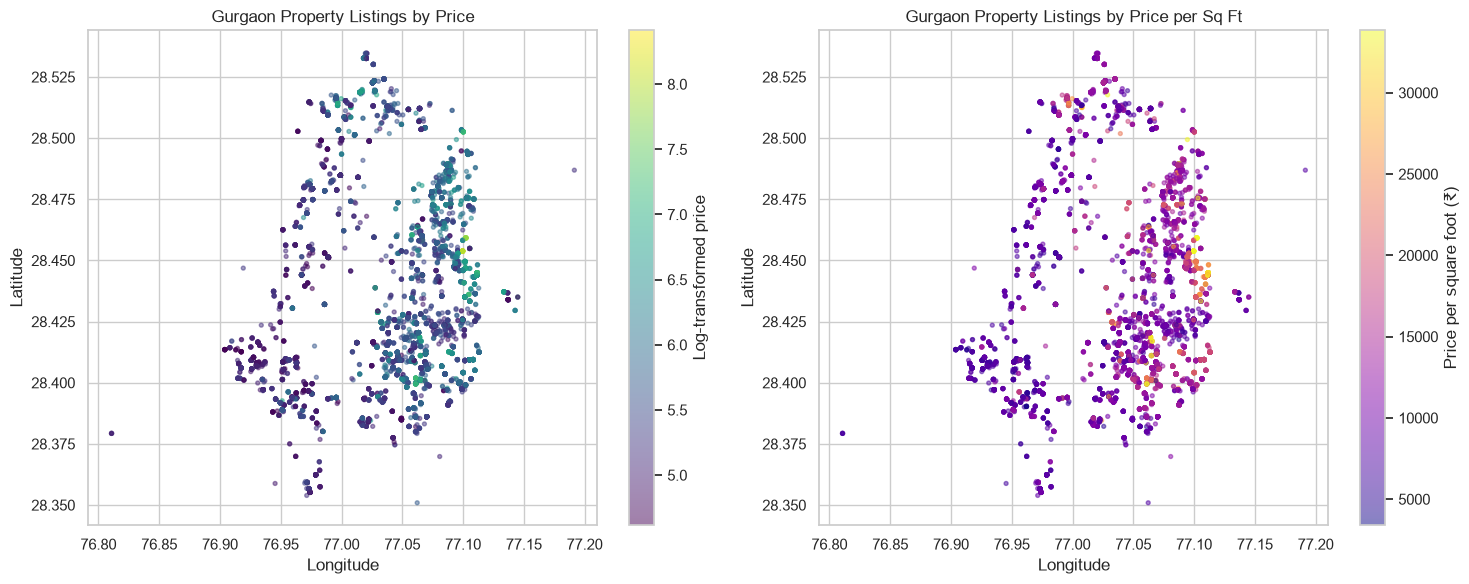

In [42]:
fig, ax = plt.subplots(1, 2, figsize=(15, 6))

# Map 1: Listings coloured by log-transformed price
sc = ax[0].scatter(
    df["longitude"],
    df["latitude"],
    c=df["log_price"],
    cmap="viridis",
    s=8,
    alpha=0.5
)

plt.colorbar(sc, ax=ax[0], label="Log-transformed price")
ax[0].set_title("Gurgaon Property Listings by Price")
ax[0].set_xlabel("Longitude")
ax[0].set_ylabel("Latitude")

# Map 2: Listings coloured by price per square foot
sc2 = ax[1].scatter(
    df["longitude"],
    df["latitude"],
    c=df["price_per_sqft"],
    cmap="plasma",
    s=8,
    alpha=0.5,
    vmax=df["price_per_sqft"].quantile(0.98)
)

plt.colorbar(sc2, ax=ax[1], label="Price per square foot (₹)")
ax[1].set_title("Gurgaon Property Listings by Price per Sq Ft")
ax[1].set_xlabel("Longitude")
ax[1].set_ylabel("Latitude")

save("05a_price_map_static")

In [43]:
coordinate_summary = (
    df.groupby("locality_grouped")[["latitude", "longitude"]]
    .nunique()
    .describe()
)

display(coordinate_summary)

,latitude,longitude
count,106.000000,106.000000
mean,10.924528,10.905660
std,11.466471,11.413049
min,2.000000,2.000000
25%,5.000000,5.000000
50%,7.500000,7.500000
75%,13.500000,12.750000
max,85.000000,84.000000


In [44]:
coordinate_counts = (
    df.groupby("locality_grouped")
    .agg(
        listings=("price_lakhs", "size"),
        unique_latitudes=("latitude", "nunique"),
        unique_longitudes=("longitude", "nunique"),
        unique_coordinate_pairs=(
            "latitude",
            lambda x: x.nunique()
        )
    )
)

# Calculate the actual number of unique latitude-longitude pairs.
coordinate_counts["unique_coordinate_pairs"] = (
    df.groupby("locality_grouped")
    .apply(
        lambda group: group[["latitude", "longitude"]]
        .drop_duplicates()
        .shape[0],
        include_groups=False
    )
)

print("Localities with the fewest unique coordinate pairs:")

display(
    coordinate_counts
    .sort_values("unique_coordinate_pairs")
    .head(15)
)

Localities with the fewest unique coordinate pairs:


,listings,unique_latitudes,unique_longitudes,unique_coordinate_pairs
locality_grouped,,,,
MG Road,18,2,2,2
Sector 26 Gurgaon,24,2,2,2
Sector 110 A Gurgaon,12,2,2,2
Sector 3 Gurgaon,24,2,2,2
Sector 36A Gurgaon,12,2,2,2
Sector 40 Gurgaon,21,2,2,2
Sector-33 Sohna,29,2,2,2
Sector 89 A Gurgaon,15,2,2,2
Sector 30 Gurgaon,14,3,3,3


In [45]:
try:
    import folium
    import branca.colormap as cm

    print("Folium and Branca are installed.")
    print("Folium version:", folium.__version__)

except ImportError:
    print("Folium or Branca is not installed.")

Folium and Branca are installed.
Folium version: 0.20.0


In [46]:
map_cols = [
    "latitude",
    "longitude",
    "price_lakhs",
    "price_per_sqft",
    "area_sqft",
    "locality_grouped"
]

map_df = df[map_cols].dropna().copy()

map_df = map_df[
    np.isfinite(map_df["latitude"]) &
    np.isfinite(map_df["longitude"]) &
    np.isfinite(map_df["price_lakhs"]) &
    np.isfinite(map_df["price_per_sqft"]) &
    np.isfinite(map_df["area_sqft"])
]

sample = map_df.sample(
    n=min(3000, len(map_df)),
    random_state=42
)

print("Available listings for mapping:", len(map_df))
print("Listings selected for interactive map:", len(sample))

Available listings for mapping: 7457
Listings selected for interactive map: 3000


In [48]:
import folium
import branca.colormap as cm
import os

# Set price-per-square-foot color range
lo, hi = map_df["price_per_sqft"].quantile([0.02, 0.98])

if lo == hi:
    hi = lo + 1

cmap = cm.LinearColormap(
    colors=["blue", "yellow", "red"],
    vmin=lo,
    vmax=hi,
    caption="Price per square foot (₹)"
)

# Center the map on the property listings
map_center = [
    map_df["latitude"].mean(),
    map_df["longitude"].mean()
]

# Use OpenStreetMap tiles instead
m = folium.Map(
    location=map_center,
    zoom_start=12,
    tiles="OpenStreetMap"
)

# Add property markers
for _, r in sample.iterrows():

    price_color = cmap(
        min(max(r["price_per_sqft"], lo), hi)
    )

    tooltip_text = (
        f"Locality: {r['locality_grouped']}<br>"
        f"Price: ₹{r['price_lakhs']:.1f} lakhs<br>"
        f"Area: {r['area_sqft']:.0f} sqft<br>"
        f"Price/sqft: ₹{r['price_per_sqft']:.0f}"
    )

    folium.CircleMarker(
        location=[r["latitude"], r["longitude"]],
        radius=3,
        weight=0,
        fill=True,
        fill_opacity=0.6,
        color=price_color,
        fill_color=price_color,
        tooltip=tooltip_text
    ).add_to(m)

# Add the color legend
cmap.add_to(m)

# Save the map
os.makedirs("../reports", exist_ok=True)

map_path = "../reports/price_map.html"
m.save(map_path)

print("Interactive map saved to:", os.path.abspath(map_path))
print("Listings displayed:", len(sample))

Interactive map saved to: d:\real-estate-price-prediction\reports\price_map.html
Listings displayed: 3000


In [49]:
figure_path = "../reports/figures/05a_price_map_static.png"
html_path = "../reports/price_map.html"

print(
    "Static map:",
    "Saved" if os.path.exists(figure_path) else "Not found"
)

print(
    "Interactive map:",
    "Saved" if os.path.exists(html_path) else "Not found"
)

Static map: Saved
Interactive map: Saved
